In [1]:
import tempfile
from pathlib import Path
import urllib.request
import xarray as xr
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt

In [ ]:
# create dataset as per variable
# function for hyras data import
# function for Copernicus surface soil moisture
# imports nc, crop to study area, subset to study period, transform to one crs

In [2]:
# load Brandenburg shapefile for masking
BB_SHAPE = gpd.read_file("../data/brandenburg_shape/pos_1/GRENZE_184201-5683624_ortsteile.gpkg", layer="bebb_0")
BB_REGIO = gpd.read_file("../data/brandenburg_shape/pos_1/GRENZE_184201-5683624_ortsteile.gpkg", layer="regionen_0")
BER_SHAPE = gpd.read_file("../data/brandenburg_shape/pos_1/GRENZE_184201-5683624_ortsteile.gpkg", layer="berlinflaeche_0")

In [3]:
for name, gdf in {
    "bebb": BB_SHAPE,
    "regionen": BB_REGIO,
    "berlin": BER_SHAPE,
}.items():
    print(f"\n--- {name} ---")
    print("CRS:", gdf.crs)
    print("Geometry:", gdf.geom_type.value_counts().to_dict())
    print("Features:", len(gdf))
    print("Bounds:", gdf.total_bounds)


--- bebb ---
CRS: EPSG:25833
Geometry: {'MultiPolygon': 1}
Features: 1
Bounds: [ 250152.04399956 5690474.94199963  483779.5        5935134.13099976]

--- regionen ---
CRS: EPSG:25833
Geometry: {'MultiPolygon': 5}
Features: 5
Bounds: [ 250152.04399956 5690474.94199963  483779.5        5935134.13099976]

--- berlin ---
CRS: EPSG:25833
Geometry: {'MultiPolygon': 1}
Features: 1
Bounds: [ 370000.82499989 5799520.65999968  415786.55299999 5837259.26999969]


In [4]:
# transform to match HYRAS CRS
beb_3035 = BB_SHAPE.to_crs("EPSG:3035")
regionen_3035 = BB_REGIO.to_crs("EPSG:3035")
berlin_3035 = BER_SHAPE.to_crs("EPSG:3035")

In [5]:
# set up a buffer of 10km around beb shape for boundingbox
buffer_m = 10 * 1000
xmin, ymin, xmax, ymax = beb_3035.total_bounds

# Add margin
xmin -= buffer_m
xmax += buffer_m
ymin -= buffer_m
ymax += buffer_m

bbox = box(xmin, ymin, xmax, ymax)

print(f"Bounds: {xmin}, {ymin}, {xmax}, {ymax}")

Bounds: 4395741.2726127915, 3135433.272509525, 4660861.186132561, 3400086.0423703673


In [6]:
# transform bbox to geodataframe
bbox_gdf = gpd.GeoDataFrame({"name":["StudyArea"]}, geometry=[bbox], crs="EPSG:3035")

In [7]:
# export bbox for main
bbox_gdf.to_file("../data/study_area.gpkg", layer="study_area", driver="GPKG")

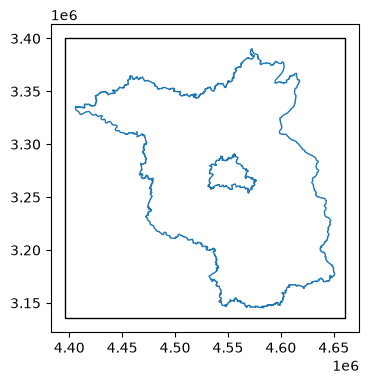

In [7]:
ax = bbox_gdf.plot(
    facecolor="none",
    edgecolor="black",
    figsize=(4, 4),
)

beb_3035.boundary.plot(
    ax=ax,
    linewidth=1,
)

berlin_3035.boundary.plot(
    ax=ax,
    linewidth=1,
)

ax.set_aspect("equal")

In [ ]:
# manually download and inspect 2014 
pr = xr.open_dataset("../data/pr_hyras_1_2014_v6-1_de.nc", engine="netcdf4")
print(f"________________pr:")
print(pr.coords)
print(len(pr.x))
print(len(pr.y))
print(len(pr.time))

print(f"________________tas:")
tas = xr.open_dataset("../data/tas_hyras_1_2014_v6-1_de.nc", engine="netcdf4")
print(tas.coords)
print(len(tas.x))
print(len(tas.y))
print(len(tas.time))

print(f"________________tasmax:")
tmax = xr.open_dataset("../data/tasmax_hyras_1_2014_v6-1_de.nc", engine="netcdf4")
print(tmax.coords)
print(len(tmax.x))
print(len(tmax.y))
print(len(tmax.time))

________________pr:
Coordinates:
  * x        (x) float64 5kB 4.022e+06 4.022e+06 ... 4.684e+06 4.686e+06
    lat      (y, x) float64 5MB ...
    lon      (y, x) float64 5MB ...
  * y        (y) float64 7kB 2.674e+06 2.676e+06 ... 3.562e+06 3.564e+06
  * time     (time) datetime64[ns] 3kB 2014-01-01T06:00:00 ... 2014-12-31T06:...
665
890
365
________________tas:
Coordinates:
  * time     (time) datetime64[ns] 3kB 2014-01-01 2014-01-02 ... 2014-12-31
  * x        (x) float64 5kB 4.022e+06 4.022e+06 ... 4.684e+06 4.686e+06
    lon      (y, x) float64 5MB ...
    lat      (y, x) float64 5MB ...
  * y        (y) float64 7kB 2.674e+06 2.676e+06 ... 3.562e+06 3.564e+06
665
890
365
________________tasmin:
Coordinates:
  * time     (time) datetime64[ns] 3kB 2014-01-01 2014-01-02 ... 2014-12-31
  * y        (y) float64 7kB 2.674e+06 2.676e+06 ... 3.562e+06 3.564e+06
  * x        (x) float64 5kB 4.022e+06 4.022e+06 ... 4.684e+06 4.686e+06
    lon      (y, x) float64 5MB ...
    lat      (y, x) f

(4395741.2726127915, 3135433.272509525, 4660861.186132561, 3400086.0423703673)


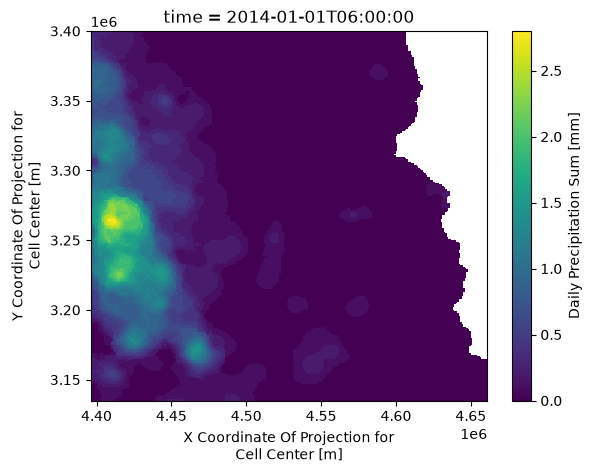

In [9]:
# test cropping pr
print(bbox.bounds)
pr_beb = pr.sel(x=slice(xmin, xmax), y=slice(ymin, ymax))
pr_beb.pr.sel(time="2014-01-01").plot()


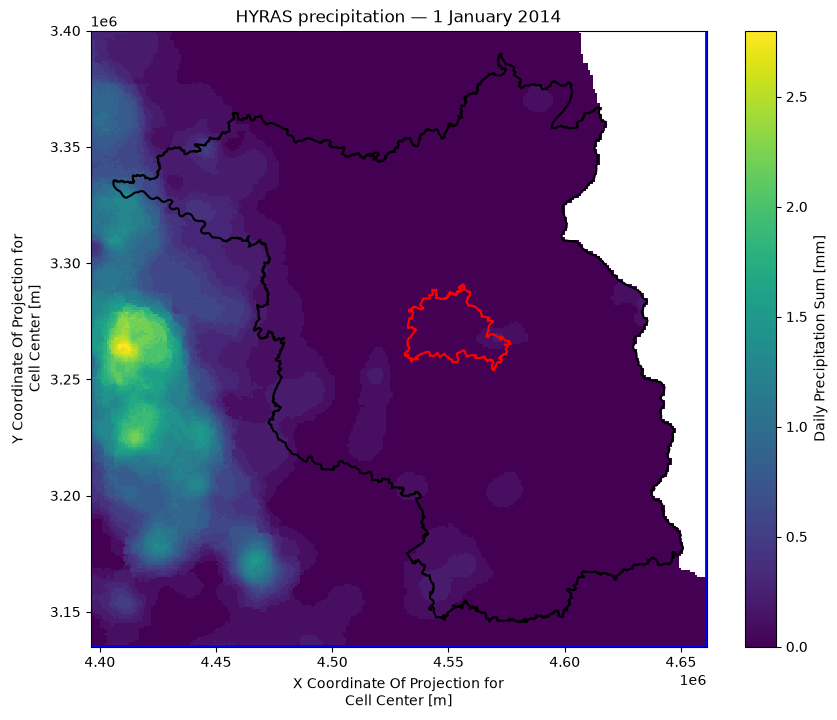

In [10]:
fig, ax = plt.subplots(figsize=(10, 8))

pr_beb.pr.sel(time="2014-01-01").plot(
    ax=ax
)

beb_3035.boundary.plot(
    ax=ax,
    edgecolor="black",
    linewidth=1.5,
)

berlin_3035.boundary.plot(
    ax=ax,
    edgecolor="red",
    linewidth=1.5,
)

bbox_gdf.boundary.plot(
    ax=ax,
    edgecolor="blue",
    linewidth=2,
)

ax.set_aspect("equal")
ax.set_title("HYRAS precipitation — 1 January 2014")

plt.show()

In [ ]:
#NOTE: import pr hyras files from dwd opendata to a tempfolder, extract and remove tempfolder in the end
""""
for y in YEARS:
    fn = f"pr_hyras_1_{y}_v6-1_de.nc"

    with tempfile.TemporaryDirectory() as tmpdir:

        local_file = Path(tmpdir) / fn

        #download
        print(f"downloading: {y}...")
        urllib.request.urlretrieve(BASE_URL + fn, local_file)

        #open nc file
        with xr.open_dataset(local_file) as ds:
            print(ds)

            ds_region = ds.sel(x=slice(xmin, xmax), y=slice(ymin,ymax))
"""


In [ ]:
#NOTE: create a function to load all hyras variables from dwd (pr, tas, tasmin, tasmax)

HYRAS_VARIABLES = {"pr": {"directory": "precipitation", "filename": "pr_hyras_1_{year}_v6-1_de.nc"},
                   "tas": {"directory": "air_temperature_mean", "filename": "tas_hyras_1_{year}_v6-1_de.nc"},
                   "tasmax": {"directory": "air_temperature_max", "filename": "tasmax_hyras_1_{year}_v6-1_de.nc"}
                   }
BASE_URL = "https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de"


def load_hyras_year(year, variables, xmin, xmax, ymin, ymax):
    """"
    Download, crop and load selected HYRAS variable from DWD per one year into
    an xarray dataset. 
    Inputs: year (int), variables (list[str]), xmin ... ymax (float) (in EPSG:3035)
    Return: xarray.DataArray
    """
    datasets = []
    lat = None
    lon = None
    
    with tempfile.TemporaryDirectory() as tmpdir:
        tmpdir = Path(tmpdir)
        for var in variables:
            # configure path to variable
            config = HYRAS_VARIABLES[var]
            fn = config["filename"].format(year=year)
            url = (f"{BASE_URL}/{config['directory']}/{fn}")
            local_file = tmpdir / fn

            # download variable
            print(f"Downloading {var}: {fn}...")
            urllib.request.urlretrieve(url, local_file)

            # open file
            with xr.open_dataset(local_file, engine="netcdf4") as ds:
                # crop to study area
                ds_region = ds.sel(x=slice(xmin,xmax), y=slice(ymin,ymax))
                if lat is None:
                    lat = ds_region["lat"].load()
                    lon = ds_region["lon"].load()
                # extract variable
                da = ds_region[var]
                # normalize timesteps
                da = da.assign_coords(time=da.time.values.astype("datetime64[D]"))
                # remove lat/lon, causes errors when merging otherwise
                da = da.drop_vars(["lat", "lon"], errors="ignore")
                # load into memory
                da = da.load()
                # append to datasets
                datasets.append(da.to_dataset(name=var))

    # combine variables
    ds_year = xr.merge(datasets, join="exact", compat="override")

    # add coords again
    ds_year = ds_year.assign_coords(lat=lat, lon=lon)

    return ds_year


In [ ]:
#NOTE: import function for hyras 

HYRAS_VARIABLES = {"pr": {"directory": "precipitation", "filename": "pr_hyras_1_{year}_v6-1_de.nc"},
                   "tas": {"directory": "air_temperature_mean", "filename": "tas_hyras_1_{year}_v6-1_de.nc"},
                   "tasmax": {"directory": "air_temperature_max", "filename": "tasmax_hyras_1_{year}_v6-1_de.nc"}
                   }
BASE_URL = "https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de"

""""
function can handle:

constructing the DWD URL
downloading one year at a time
temporary files
opening NetCDF
selecting the study area
normalizing timestamps
checking the expected variable
handling the leap year naturally
loading the data
concatenating years
returning the standardized variable
"""


def import_hyras(variable, startyear, endyear, bbox):
    """"
    Download, crop, subset and load a selected HYRAS variable from DWD for a specified study period into
    an xarray dataset. 
    Inputs: variable [str], startyear/endyear [int], bbox [str](float) (in EPSG:3035)
    Return: xarray.DataArray
    """
    datasets = []
    lat = None
    lon = None
    
    with tempfile.TemporaryDirectory() as tmpdir:
        tmpdir = Path(tmpdir)
        for var in variables:
            # configure path to variable
            config = HYRAS_VARIABLES[var]
            fn = config["filename"].format(year=year)
            url = (f"{BASE_URL}/{config['directory']}/{fn}")
            local_file = tmpdir / fn

            # download variable
            print(f"Downloading {var}: {fn}...")
            urllib.request.urlretrieve(url, local_file)

            # open file
            with xr.open_dataset(local_file, engine="netcdf4") as ds:
                # crop to study area
                ds_region = ds.sel(x=slice(xmin,xmax), y=slice(ymin,ymax))
                if lat is None:
                    lat = ds_region["lat"].load()
                    lon = ds_region["lon"].load()
                # extract variable
                da = ds_region[var]
                # normalize timesteps
                da = da.assign_coords(time=da.time.values.astype("datetime64[D]"))
                # remove lat/lon, causes errors when merging otherwise
                da = da.drop_vars(["lat", "lon"], errors="ignore")
                # load into memory
                da = da.load()
                # append to datasets
                datasets.append(da.to_dataset(name=var))

    # combine variables
    ds_year = xr.merge(datasets, join="exact", compat="override")

    # add coords again
    ds_year = ds_year.assign_coords(lat=lat, lon=lon)

    return ds_year


In [ ]:
VARIABLES = ["pr", "tas", "tasmax"]

hyras_2014 = load_hyras_year(year=2014,variables=VARIABLES,xmin=xmin, xmax=xmax, ymin=ymin, ymax=ymax)

print(hyras_2014)

<xarray.Dataset> Size: 719MB
Dimensions:  (x: 265, y: 265, time: 365)
Coordinates:
  * x        (x) float64 2kB 4.396e+06 4.398e+06 4.398e+06 ... 4.66e+06 4.66e+06
    lat      (y, x) float64 562kB 51.33 51.33 51.33 51.32 ... 53.6 53.6 53.59
    lon      (y, x) float64 562kB 11.08 11.1 11.11 11.13 ... 15.1 15.12 15.13
  * y        (y) float64 2kB 3.136e+06 3.136e+06 3.138e+06 ... 3.398e+06 3.4e+06
  * time     (time) datetime64[s] 3kB 2014-01-01 2014-01-02 ... 2014-12-31
Data variables:
    pr       (time, y, x) float32 103MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan
    tas      (time, y, x) float64 205MB 1.5 1.5 1.6 1.5 1.6 ... nan nan nan nan
    tasmin   (time, y, x) float64 205MB -1.0 -1.0 -0.9 -1.1 ... nan nan nan nan
    tasmax   (time, y, x) float64 205MB 4.4 4.4 4.5 4.5 4.7 ... nan nan nan nan


In [ ]:
# load all years and vars
YEARS = range(2014, 2020)
VARIABLES = ["pr", "tas", "tasmax"]

In [ ]:
hyras_years = {}

for yr in YEARS:
    hyras_years[yr] = load_hyras_year(year=yr, variables=VARIABLES,xmin=xmin,xmax=xmax,ymin=ymin, ymax=ymax)
    print(hyras_years[yr])